In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv('play_tennis.csv')
df = df.drop(columns=['day'])
df

,outlook,temp,humidity,wind,play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [ ]:
le = {}
df_enc = df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

In [ ]:
x = df_enc.drop(columns=['play'])
y = df_enc['play']

model = CategoricalNB()
model.fit(x, y)

CategoricalNB()

In [ ]:
test = [['sunny', 'cool', 'high', 'strong']]

print("\n----prediction------------------------")
for t in test:
    row = pd.DataFrame([[
        le['outlook'].transform([t[0].title()])[0],
        le['temp'].transform([t[1].title()])[0],
        le['humidity'].transform([t[2].title()])[0],
        le['wind'].transform([t[3].title()])[0]
    ]], columns=x.columns)
    pred = le['play'].inverse_transform(model.predict(row))[0]
    prob = model.predict_proba(row)[0]
    print(f"Input: Outlook={t[0].title()}, Temp={t[1].title()}, Humidity={t[2].title()}, Wind={t[3].title()}")
    print(f"Result: Play Tennis -> {pred}")
    print(f"p(No)  = {prob[0]:.4f}")
    print(f"p(Yes) = {prob[1]:.4f}")


----prediction------------------------
Input: Outlook=Sunny, Temp=Cool, Humidity=High, Wind=Strong
Result: Play Tennis -> No
p(No)  = 0.7201
p(Yes) = 0.2799


In [ ]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


Training Accuracy: 92.86%


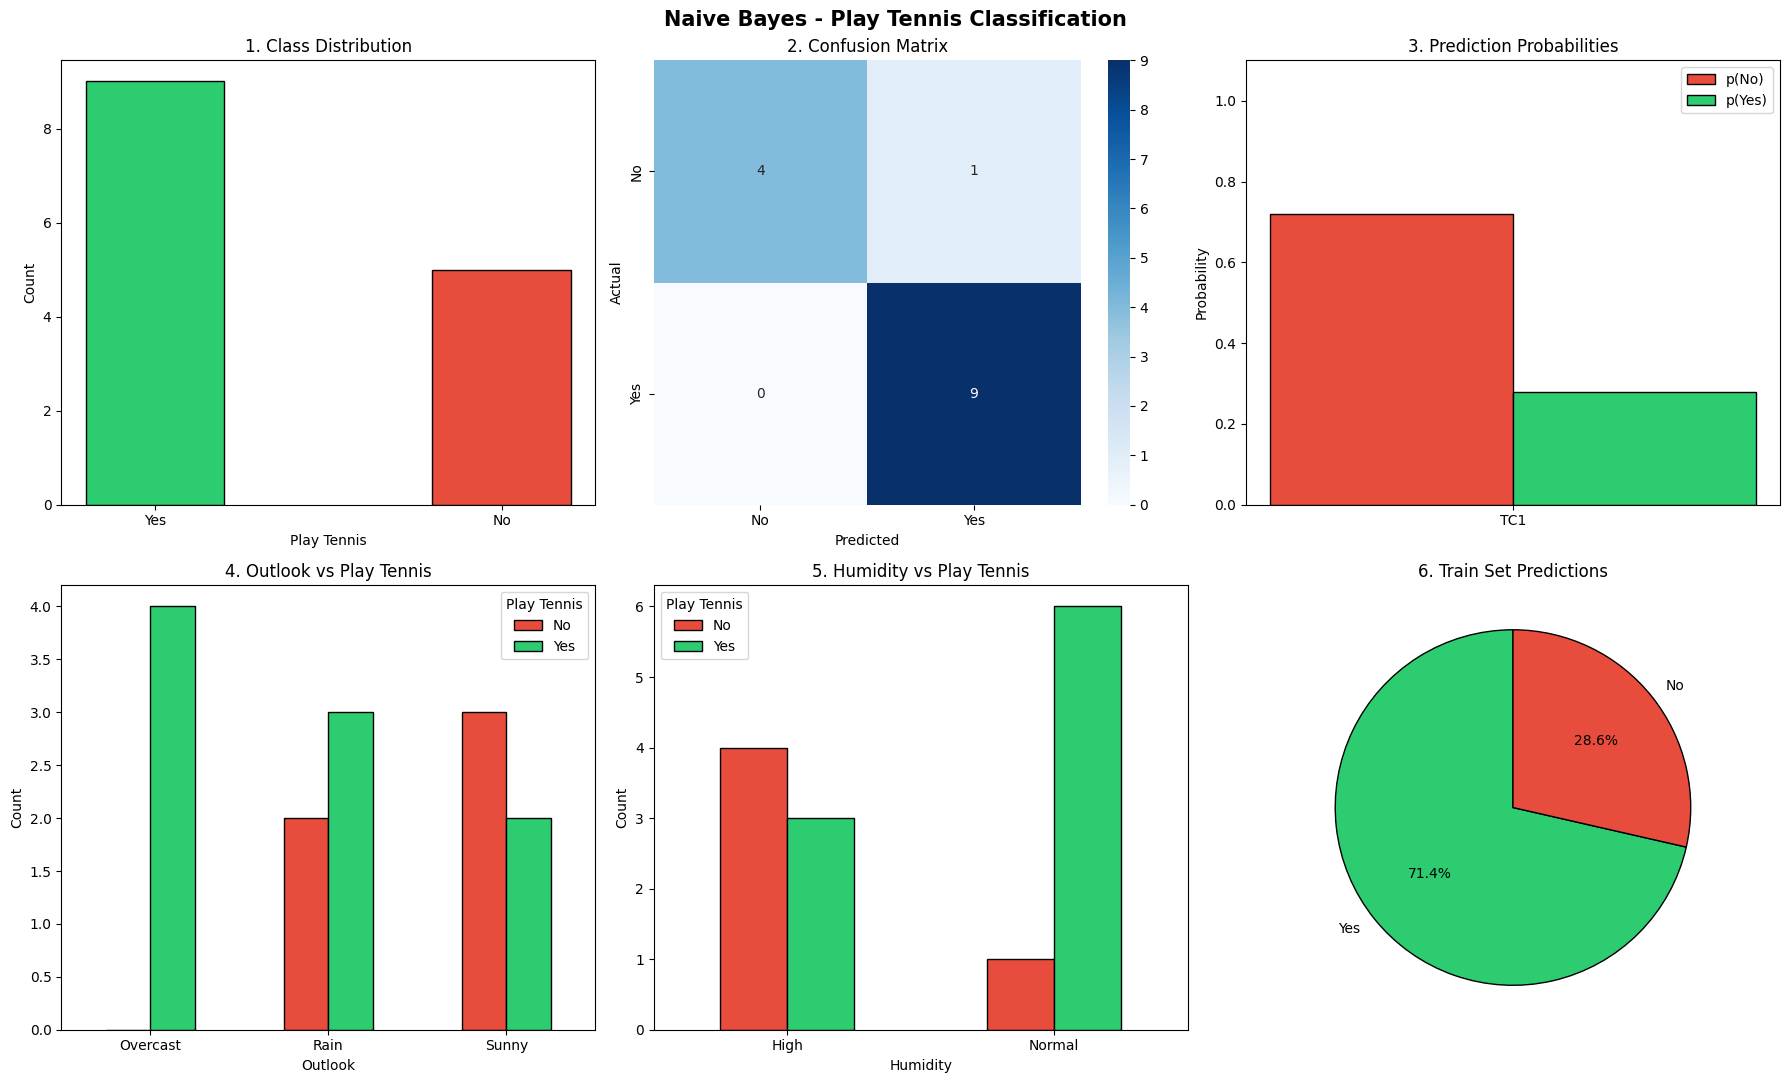

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Play Tennis Classification", fontsize=15, fontweight="bold")

# 1. Class Distribution
counts = df['play'].value_counts()
axes[0,0].bar(counts.index, counts.values,
              color=['#2ecc71' if i == 'Yes' else '#e74c3c' for i in counts.index],
              edgecolor='black', width=0.4)
axes[0,0].set_title("1. Class Distribution")
axes[0,0].set_xlabel("Play Tennis")
axes[0,0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[0,1],
            xticklabels=le['play'].classes_, yticklabels=le['play'].classes_)
axes[0,1].set_title("2. Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_axis = np.arange(len(tc_labels))
width = 0.3
prob_no, prob_yes = [], []
for t in test:
    row = pd.DataFrame([[
        le['outlook'].transform([t[0].title()])[0],
        le['temp'].transform([t[1].title()])[0],
        le['humidity'].transform([t[2].title()])[0],
        le['wind'].transform([t[3].title()])[0]
    ]], columns=x.columns)
    prob = model.predict_proba(row)[0]
    prob_no.append(prob[0])
    prob_yes.append(prob[1])

axes[0,2].bar(x_axis - width/2, prob_no, width, label='p(No)', color='#e74c3c', edgecolor='black')
axes[0,2].bar(x_axis + width/2, prob_yes, width, label='p(Yes)', color='#2ecc71', edgecolor='black')
axes[0,2].set_title("3. Prediction Probabilities")
axes[0,2].set_xticks(x_axis)
axes[0,2].set_xticklabels(tc_labels)
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4. Outlook vs Play
outlook_counts = df.groupby(['outlook', 'play']).size().unstack(fill_value=0)
outlook_counts.plot(kind='bar', ax=axes[1,0], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,0].set_title("4. Outlook vs Play Tennis")
axes[1,0].set_xlabel("Outlook")
axes[1,0].set_ylabel("Count")
axes[1,0].legend(title="Play Tennis")

# 5. Humidity vs Play
hum_counts = df.groupby(['humidity', 'play']).size().unstack(fill_value=0)
hum_counts.plot(kind='bar', ax=axes[1,1], color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0)
axes[1,1].set_title("5. Humidity vs Play Tennis")
axes[1,1].set_xlabel("Humidity")
axes[1,1].set_ylabel("Count")
axes[1,1].legend(title="Play Tennis")

# 6. Pie Chart
pred_counts = pd.Series(y_pred).value_counts()
pred_counts.index = le['play'].inverse_transform(pred_counts.index)
colors_pred = ['#2ecc71' if l == 'Yes' else '#e74c3c' for l in pred_counts.index]
axes[1,2].pie(pred_counts, labels=pred_counts.index, colors=colors_pred,
              autopct='%1.1f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6. Train Set Predictions")

plt.tight_layout()
plt.show()